# Supplementary Fig. S13: the Schubert and Glänzel citation network

This notebook builds the country citation network of the 2017 publications and its country-randomized version, applies the Schubert and Glänzel normalization, and draws Supplementary Fig. S13. It also prints the Spearman correlations between the original and randomized raw and normalized citation networks reported in Supplementary Note 9.

It reads `citation_network_2017.csv.gz` from the data folder (`path2data`), made by `data_prep/make_data_FigS13_S18.py` from the publication-level citation data. The figure is saved in the `figures` folder.

In [1]:
import os
import json
import gzip
import itertools
from itertools import chain
from collections import defaultdict
import pandas as pd
import numpy as np
import networkx as nx

import scipy.sparse as spsparse
import scipy.stats as spstats

from statsmodels.stats.multitest import multipletests as holm
import statsmodels.api as sm

import matplotlib.pylab as plt
import matplotlib.gridspec as gridspec
import matplotlib.transforms as mtransforms
import seaborn as sns

from sklearn.preprocessing import normalize

import scienceplots
plt.style.use('science')

# set this path to where the processed data (Source Data) is stored:
path2sourcedata = "Source Data"
# when the notebook is run from the code folder, the Source Data folder is one level up
if not os.path.exists(path2sourcedata):
    path2sourcedata = os.path.join("..", "Source Data")

# the processed input data are in the data folder, next to the Source Data folder
path2data = os.path.join(os.path.dirname(os.path.abspath(path2sourcedata)), 'data')

# the regenerated figures are saved in the figures folder
path2figures = os.path.join(os.path.dirname(os.path.abspath(path2sourcedata)), 'figures')
os.makedirs(path2figures, exist_ok=True)
os.makedirs(os.path.join(path2figures, 'networks'), exist_ok=True)

## The country citation network of the 2017 publications

In [2]:
# the countries of the 2017 co-authorship network, as for Supplementary Fig. S11
countries = np.sort(pd.read_csv(os.path.join(path2data, 'countries_2017.csv.gz'))['Country'].values)
country2int = {c:i for i, c in enumerate(countries)}
int2country = {i:c for c, i in country2int.items()}
Ncountry = len(countries)

# citations from each citing country to the 2017 publications of each cited country, and the same after randomly
# permuting the cited country over the citations
ncites = pd.read_csv(os.path.join(path2data, 'citation_network_2017.csv.gz'))
ncites = ncites[ncites['CitingCountry'].isin(country2int) & ncites['CitedCountry'].isin(country2int)]
ncites = ncites[ncites['CitingCountry'] != ncites['CitedCountry']].reset_index(drop=True)

def country_matrix(weight):
    net = np.zeros((Ncountry, Ncountry))
    net[ncites['CitingCountry'].map(country2int).values, ncites['CitedCountry'].map(country2int).values] = ncites[weight].values
    return net

citenet = country_matrix('Citations')
randcitenet = country_matrix('RandomizedCitations')

# Supplementary Note 9: correlation between the original and randomized raw and normalized citation networks
print('raw citation network:', spstats.spearmanr(citenet[citenet > 0], randcitenet[citenet > 0]))
normcitenet = normalize(citenet, norm='l1', axis=1)
normrandcitenet = normalize(randcitenet, norm='l1', axis=1)
print('normalized citation network:', spstats.spearmanr(normcitenet[normcitenet > 0], normrandcitenet[normcitenet > 0]))

raw citation network: SignificanceResult(statistic=0.9169897425157084, pvalue=0.0)
normalized citation network: SignificanceResult(statistic=0.7655716422490824, pvalue=0.0)


## The Schubert and Glänzel normalization

In [3]:
def Schubert_Glanzel_normalization(net):
    """Observed share of the references from country i to country j over the share expected from country j's
    presence in the citation system excluding country i."""
    N = net.shape[0]

    total = net.sum()

    row_sum_mat = net.sum(axis=1).repeat(N).reshape((N,N))
    col_sum_mat = net.sum(axis=0).repeat(N).reshape((N,N)).T

    ishare = normalize(net, norm='l1', axis=1)
    jshare = col_sum_mat / (total - row_sum_mat)

    return ishare / jshare


citesg = Schubert_Glanzel_normalization(citenet)
rcitesg = Schubert_Glanzel_normalization(randcitenet)

citesg0 = citesg[citesg > 0]
print((citesg0 > 1).sum(), "edges above 1,", (citesg0 < 1).sum(), "edges below 1")

# the number of incoming and outgoing edges bigger than 1 of each country
numincoming = (citesg > 1).sum(axis=0)
numoutgoing = (citesg > 1).sum(axis=1)

16589 edges above 1, 14276 edges below 1


## Supplementary Fig. S13

B SignificanceResult(statistic=-0.19468424060485437, pvalue=2.610144547062209e-261)
C PearsonRResult(statistic=0.9236897810261827, pvalue=4.849557151370209e-94)


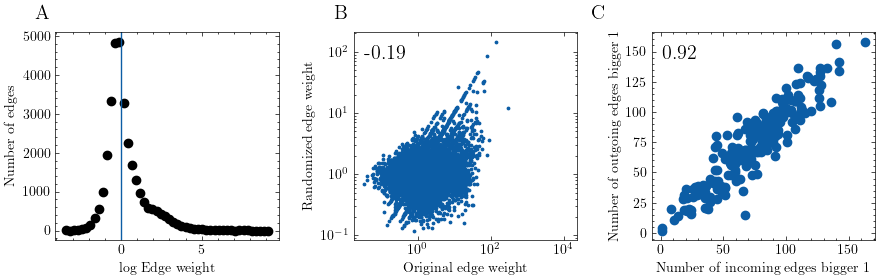

In [4]:
dist, bins = np.histogram(np.log(citesg[citesg > 0]), bins=50)

fig, ax = plt.subplots(1, 3, figsize=(9, 3))

ax[0].scatter(bins[:-1], dist, color='k')
ax[0].axvline(x=0)

ax[0].set_ylabel('Number of edges')
ax[0].set_xlabel('log Edge weight')

ax[1].scatter(citesg[citesg > 0], rcitesg[citesg > 0], s=3)
ax[1].set_xscale('log')
ax[1].set_yscale('log')

ax[1].set_ylabel('Randomized edge weight')
ax[1].set_xlabel('Original edge weight')

corr_b = spstats.spearmanr(citesg[citesg > 0], rcitesg[citesg > 0])
print('B', corr_b)
corr_trans = mtransforms.ScaledTranslation(0.1, -0.3, fig.dpi_scale_trans)
ax[1].text(0.0, 1.0, str(np.round(corr_b.statistic, 2)), transform=ax[1].transAxes + corr_trans,
           fontsize='x-large', va='bottom')

trans = mtransforms.ScaledTranslation(-0.2, 7/72, fig.dpi_scale_trans)
ax[0].text(0.0, 1.0, 'A', transform=ax[0].transAxes + trans, fontsize='x-large', va='bottom')
ax[1].text(0.0, 1.0, 'B', transform=ax[1].transAxes + trans, fontsize='x-large', va='bottom')

lax = ax[2]
lax.scatter(numincoming, numoutgoing)
corr_c = spstats.pearsonr(numincoming, numoutgoing)
print('C', corr_c)

trans = mtransforms.ScaledTranslation(0.1, -0.3, fig.dpi_scale_trans)
lax.text(0.0, 1.0, str(np.round(corr_c.statistic, 2)), transform=lax.transAxes + trans,
         fontsize='x-large', va='bottom')

trans = mtransforms.ScaledTranslation(-0.6, 7/72, fig.dpi_scale_trans)
lax.text(0.0, 1.0, 'C', transform=lax.transAxes + trans, fontsize='x-large', va='bottom')

lax.set_ylabel('Number of outgoing edges bigger 1', fontsize=10)
lax.set_xlabel('Number of incoming edges bigger 1', fontsize=10)

plt.tight_layout()
plt.savefig(os.path.join(path2figures, 'FigSI_sgcitenetwork.pdf'))
plt.savefig(os.path.join(path2figures, 'FigSI_sgcitenetwork.png'))
plt.show()

## Source Data for Supplementary Figure 13

The values plotted, written to `Source Data/SourceData_FigS13.xlsx`.

In [5]:
# the Source Data helpers (sourcedatautils.py, in the code folder like vizutils.py)
from sourcedatautils import write_source_data

title = 'Supplementary Figure 13: Schubert and Glanzel citation network.'
description = ('Schubert and Glanzel normalized citation network of the 2017 publications (citations within 5 years, '
               'without author self-citations and same-affiliation citations): the observed share of the references '
               'from the citing country to the cited country over the expected share. The randomized network permutes the '
               'cited country over the citations. A) Edge weight distribution (log edge weight, 50 bins). '
               'B) Edge weights of the original and randomized networks (Spearman correlation). C) Number of incoming and '
               'outgoing edges bigger than 1 of each country (Pearson correlation).')

hist = pd.DataFrame({'log edge weight (bin lower edge)':bins[:-1], 'log edge weight (bin upper edge)':bins[1:],
                     'Number of edges':dist})
rows, cols = np.nonzero(citesg > 0)
weights = pd.DataFrame({'Citing country':[int2country[i] for i in rows], 'Cited country':[int2country[j] for j in cols],
                        'Original edge weight':citesg[rows, cols], 'Randomized edge weight':rcitesg[rows, cols]})
degrees = pd.DataFrame({'Country':countries, 'Number of incoming edges bigger 1':numincoming,
                        'Number of outgoing edges bigger 1':numoutgoing})
correlations = pd.DataFrame({'Panel':['B', 'C'], 'Correlation':['Spearman', 'Pearson'],
                             'Coefficient':[corr_b.statistic, corr_c.statistic], 'p-value':[corr_b.pvalue, corr_c.pvalue]})

write_source_data('SourceData_FigS13.xlsx', title, description,
                  [('A', 'A) Edge weight distribution.', hist),
                   ('B', 'B) Edge weights of the original and randomized networks.', weights),
                   ('C', 'C) Number of incoming and outgoing edges bigger than 1 of each country.', degrees),
                   ('Correlations', 'Correlation coefficients shown in B and C.', correlations)])

wrote /Users/psp2nq/Documents/NationalBiasCode/Source Data/SourceData_FigS13.xlsx
wrote /Users/psp2nq/Documents/NationalBiasCode/Source Data/README.txt
